# Freight rate assessment — Stage 4: Final predictions and scorer

Run the cells from top to bottom. This notebook reuses the tested Stage 4 and Stage 3 Python modules. It retrains the selected no-market-signals LightGBM model on all labeled training rows, fills the validation template and December chart inputs, validates both files, and runs the scorer.

In VS Code, select the project environment (`.\\env\\Scripts\\python.exe`) as the notebook kernel. If dependencies are missing, install them in PowerShell from the project directory:

```powershell
.\env\Scripts\python.exe -m pip install -r requirements.txt
```

The notebook overwrites `validation_predictions.csv` and fills `december-chart-inputs.csv`.

## 1. Load workflow and inputs

In [1]:
from pathlib import Path
import runpy
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
stage3 = runpy.run_path(str(ROOT / "stage3_modeling.py"))
stage4 = runpy.run_path(str(ROOT / "stage4_predictions.py"))

data = stage3["load_training_data"]()
validation = pd.read_csv(stage4["VALIDATION_PATH"])
validation["date"] = pd.to_datetime(validation["date"], errors="coerce")
template = pd.read_csv(stage4["TEMPLATE_PATH"])
december_original = pd.read_csv(stage4["DECEMBER_PATH"])

print("Training rows:", len(data))
print("Validation rows:", len(validation))
print("December rows:", len(december_original))
print("Training period:", data.date.min().date(), "to", data.date.max().date())

c:\Users\redni\Downloads\ML-Assessment\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training rows: 48000
Validation rows: 12000
December rows: 31
Training period: 2025-01-01 to 2025-10-31


## 2. Load the selected Stage 3 model parameters

The chosen model is LightGBM A, which does not require market signals.

In [2]:
parameters = stage4["load_best_parameters"]()
display(pd.Series(parameters, name="value").to_frame())

if data.date.max() >= validation.date.min():
    raise ValueError("Validation dates must be strictly after all training dates.")
if list(template.columns) != stage4["PREDICTION_COLUMNS"]:
    raise ValueError("Prediction template has unexpected columns/order.")
if set(template.load_id.astype(str)) != set(validation.load_id.astype(str)):
    raise ValueError("Template IDs do not match validation IDs.")

Using Stage 3 best trial #1 (CV MAE=$134.05): {'learning_rate': 0.0560965441457447, 'max_depth': 5, 'min_child_samples': 96, 'n_estimators': 500, 'num_leaves': 8, 'reg_lambda': 0.3002234015769267, 'include_signals': False}


,value
learning_rate,0.056097
max_depth,5
min_child_samples,96
n_estimators,500
num_leaves,8
reg_lambda,0.300223
include_signals,False


## 3. Retrain on all labeled data and predict validation

Preprocessing, including imputation, is fitted as part of the model on the full training dataset.

In [3]:
_, validation_prediction, _, target_cap = stage3["fit_variant"](
    data, validation, parameters, include_signals=False
)
predictions = template.copy()
prediction_by_id = pd.Series(
    validation_prediction,
    index=validation.load_id.astype(str),
    name="predicted_rate",
)
predictions["predicted_rate"] = predictions.load_id.astype(str).map(prediction_by_id)

print("Training target cap (p99):", round(target_cap, 2))
display(predictions.head())
display(predictions.predicted_rate.describe().round(2))

Training target cap (p99): 5972.83


,load_id,predicted_rate
0,TE-000001,840.240600
1,TE-000002,5010.339136
2,TE-000003,5269.040015
3,TE-000004,4055.001630
4,TE-000005,1798.717215


count    12000.00
mean      2339.08
std       1333.81
min        203.03
25%       1273.72
50%       2026.22
75%       3330.09
max       6149.54
Name: predicted_rate, dtype: float64

## 4. Predict December chart inputs

December has no coordinates; resolve the fixed lane coordinates from the consistent training city mappings, then apply the same no-signals model.

In [4]:
if list(december_original.columns) != stage4["DECEMBER_COLUMNS"]:
    raise ValueError("December input columns do not match the scorer's required order.")

december = december_original.copy()
december["date"] = pd.to_datetime(december["date"], errors="coerce")
coordinate_map = stage3["make_city_coordinate_map"](data)
december_with_coordinates = stage3["attach_coordinates"](december, coordinate_map)
coordinate_columns = ["pickup_lat", "pickup_lon", "delivery_lat", "delivery_lon"]
if december_with_coordinates[coordinate_columns].isna().any().any():
    raise ValueError("Could not infer coordinates for the December lane.")

_, december_prediction, _, _ = stage3["fit_variant"](
    data, december_with_coordinates, parameters, include_signals=False
)
december["predicted_rate"] = december_prediction

daily_change = december.predicted_rate.diff().abs().dropna()
mean_rate = december.predicted_rate.mean()
print(
    f"December curve: ${december.predicted_rate.min():.2f}–"
    f"${december.predicted_rate.max():.2f}; mean=${mean_rate:.2f}; "
    f"max daily change=${daily_change.max():.2f} "
    f"({daily_change.max() / mean_rate:.2%} of mean)"
)
display(december)

December curve: $821.17–$842.36; mean=$832.02; max daily change=$10.47 (1.26% of mean)


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,826.374667
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,831.595515
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,841.718934
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,839.814913
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,834.654421
5,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-06,826.143008
6,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-07,821.173497
7,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-08,824.505315
8,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-09,829.714366
9,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-10,840.185689


## 5. Validate and save the submission files

In [5]:
stage4["validate_final_files"](predictions, validation, december)
predictions.to_csv(stage4["PREDICTIONS_PATH"], index=False)
december.to_csv(stage4["DECEMBER_PATH"], index=False, date_format="%Y-%m-%d")
print("Saved:", stage4["PREDICTIONS_PATH"])
print("Updated:", stage4["DECEMBER_PATH"])
print("All output IDs/rates and required columns validated.")

Saved: C:\Users\redni\Downloads\ML-Assessment\validation_predictions.csv
Updated: C:\Users\redni\Downloads\ML-Assessment\december-chart-inputs.csv
All output IDs/rates and required columns validated.


## 6. Run the scorer and display its chart

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results\candidate_december.png
Final validation metrics are calculated by Spotter after submission.



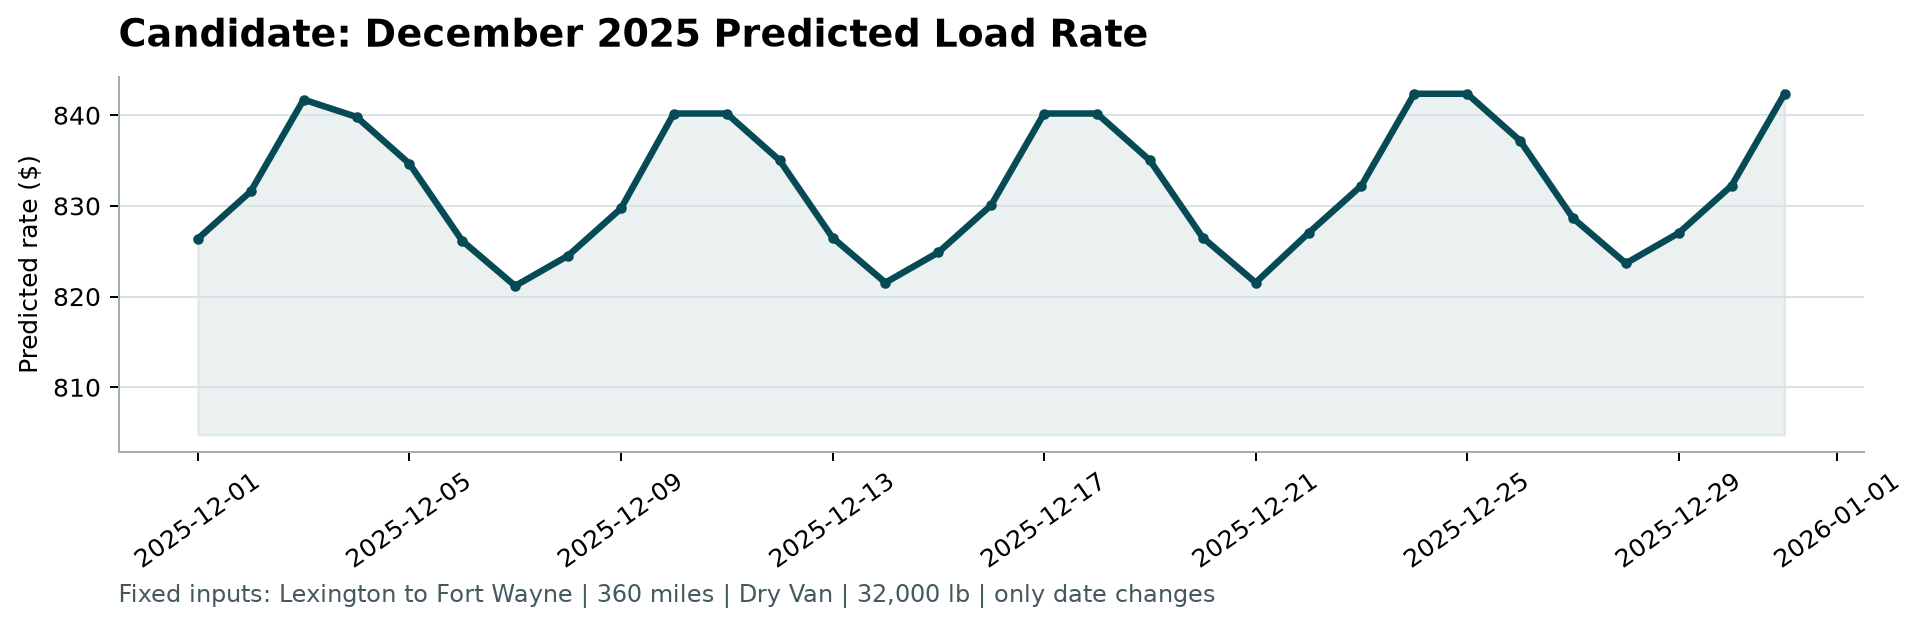

In [6]:
score_script = ROOT / "score.py"
result = subprocess.run(
    [
        sys.executable,
        str(score_script),
        "--predictions",
        str(stage4["PREDICTIONS_PATH"]),
        "--december-predictions",
        str(stage4["DECEMBER_PATH"]),
    ],
    cwd=ROOT,
    capture_output=True,
    text=True,
    check=False,
)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(f"Scorer failed with exit code {result.returncode}.")

chart_path = ROOT / "scorer_results" / "candidate_december.png"
if not chart_path.is_file():
    raise FileNotFoundError(f"Scorer chart was not created: {chart_path}")
display(Image(filename=str(chart_path)))